# 04 · Stability

Checks whether the partitions would come out the same with a slightly different sample.

`SampleDistClustering` is used here without subsampling (`frac_sample_size = 1`), so changing the random seed
gives the same partition every time. Instead, the patients are resampled:

1. Draw 216 patients with replacement (a bootstrap sample; the seed is the refit number).
2. Refit the configuration on that sample: distance, robust covariance, block variabilities and medoids
   (or centroids for k-means).
3. Assign all 216 original patients to the nearest medoid or centroid.
4. Repeat 30 times and compute the Adjusted Rand Index (ARI) between every pair of the 30 partitions (435 pairs).
   ARI = 1 means identical partitions, 0 means no more agreement than chance.

The RelMS configurations (I1, M1) are left out because the library assigns new patients with the G-Gower point
distance, so RelMS would not be refitted exactly.

In [1]:
import json, itertools

%run -i ../src/setup.ipynb

from sklearn.metrics import adjusted_rand_score

CMP = cfg.RESULTS_DIR / "02_compare_configurations"
OUT = cfg.RESULTS_DIR / "04_stability"
OUT.mkdir(parents=True, exist_ok=True)

selection = json.loads((CMP / "selection.json").read_text())
SEL, K = selection["selected"], selection["k"]
full_labels = pd.read_csv(CMP / "labels.csv")
df = load_analysis_data()

CONFIGS = [SEL] + [n for n in ["C1", "C1-b", "C2", "I2", "M2", "M3"] if n != SEL]
print("selected:", SEL, "| k =", K, "| refits =", cfg.N_STABILITY_REFITS)

selected: C1-b | k = 4 | refits = 30


## 1. Bootstrap refits

In [2]:
partitions = {}
for name in CONFIGS:
    metric = selection["m3_metric"] if name == "M3" else None
    partitions[name] = bootstrap_partitions(name, K, df, metric=metric)
    print(f"{name:5s} done")
np.savez_compressed(OUT / "bootstrap_partitions.npz", **{n.replace("-", "_"): p for n, p in partitions.items()})

C1-b  done


C1    done


C2    done


I2    done


M2    done


M3    done


## 2. Agreement between refits

- Pairwise ARI: between every pair of the 30 refits.
- ARI with the full-data partition: between each refit and the partition of notebook 02.

In [3]:
pairwise, rows = {}, []
for name, P in partitions.items():
    pw = np.array([adjusted_rand_score(P[i], P[j]) for i, j in itertools.combinations(range(len(P)), 2)])
    vs_full = np.array([adjusted_rand_score(full_labels[name], p) for p in P])
    pairwise[name] = pw
    rows.append({"configuration": name, "pairs": len(pw), "mean": pw.mean(), "SD": pw.std(ddof=1),
                 "median": np.median(pw), "min": pw.min(), "max": pw.max(),
                 "mean ARI vs full-data partition": vs_full.mean()})
summary = pd.DataFrame(rows).set_index("configuration").round(3)
summary.to_csv(OUT / "stability_summary.csv")
summary

,pairs,mean,SD,median,min,max,mean ARI vs full-data partition
configuration,,,,,,,
C1-b,435,0.762,0.115,0.784,0.345,0.950,0.827
C1,435,0.272,0.130,0.247,0.047,0.764,0.369
C2,435,0.234,0.124,0.211,0.029,0.832,0.348
I2,435,0.155,0.096,0.146,-0.045,0.681,0.204
M2,435,0.108,0.080,0.094,-0.024,0.531,0.127
M3,435,0.100,0.073,0.085,-0.043,0.449,0.128


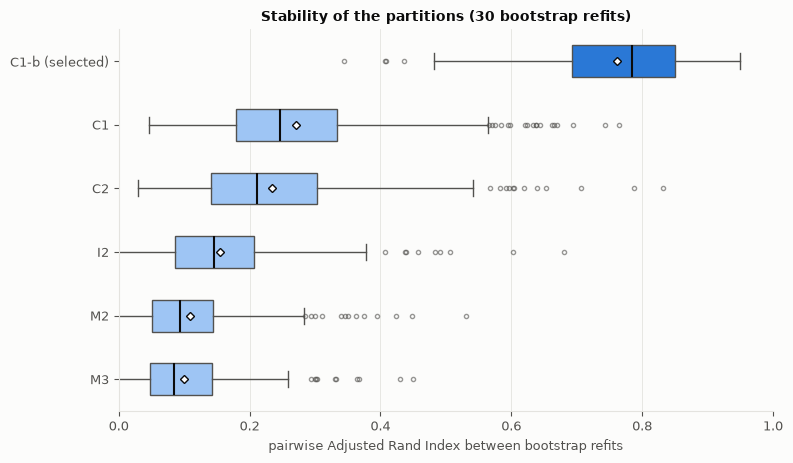

In [4]:
fig = stability_boxplot(pairwise, highlight=SEL)
fig.savefig(OUT / "stability_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Cross-check without duplicated patients

A bootstrap sample repeats some patients and leaves out others (about 37%). To check that this does not
change the ranking, the procedure is repeated with 30 subsamples of 80% of the patients drawn without
replacement (seeds 0–29), again assigning all 216 patients afterwards.

In [5]:
from sklearn.cluster import KMeans

def subsample_partitions(name, frac=0.8, n_refits=cfg.N_STABILITY_REFITS):
    c = cfg.CONFIGS[name]
    out = []
    for r in range(n_refits):
        idx = np.random.default_rng(r).choice(len(df), int(frac * len(df)), replace=False)
        if c["algorithm"] == "kmeans":
            X = build_kmeans_matrix(df, c)["X"]
            out.append(KMeans(K, random_state=cfg.RANDOM_STATE, n_init=cfg.KMEANS_N_INIT).fit(X[idx]).predict(X))
            continue
        d = build_design(df, c)
        m = ExactRelMSSampleDistClustering(
            make_pam(K), metric=selection["m3_metric"] if name == "M3" else c["metric"],
            frac_sample_size=cfg.FRAC_SAMPLE_SIZE, random_state=cfg.RANDOM_STATE,
            p1=d["p1"], p2=d["p2"], p3=d["p3"], d1=d["d1"], d2=d["d2"], d3=d["d3"],
            robust_method=cfg.ROBUST_METHOD, alpha=cfg.ALPHA).fit(d["X"][idx])
        out.append(np.asarray(m.predict(d["X"])).astype(int))
    return out

rows = []
for name in CONFIGS:
    P = subsample_partitions(name)
    pw = np.array([adjusted_rand_score(P[i], P[j]) for i, j in itertools.combinations(range(len(P)), 2)])
    rows.append({"configuration": name, "mean": pw.mean(), "median": np.median(pw), "min": pw.min()})
sub = pd.DataFrame(rows).set_index("configuration").round(3)
sub.to_csv(OUT / "stability_subsampling80.csv")
sub

,mean,median,min
configuration,,,
C1-b,0.873,0.891,0.649
C1,0.448,0.408,0.086
C2,0.387,0.336,0.087
I2,0.408,0.332,0.087
M2,0.276,0.175,0.027
M3,0.266,0.193,0.034


## 4. Interpretation

- The selected configuration is stable: C1-b's refits agree with each other at a mean pairwise ARI of about
  0.76 (median about 0.78) and with the full-data partition at about 0.83; with 80% subsamples the agreement is
  about 0.87.
- The k-medoids partitions are much less reproducible (C1 about 0.27, C2 about 0.23, and 0.10 to 0.16 for the
  configurations with images). The ranking is the same without duplicated patients, and keeping C1's full-data
  distance fixed and only re-running PAM on subsamples gives a similar value (about 0.35). With the patients
  forming a continuum (silhouettes ≤ 0.16, notebook 01), many different sets of four medoids fit almost equally
  well.
- Together with the PSI, this supports C1-b: it separates the interpretation variables most clearly and its
  partition is reproducible. The partitions of C1 and of the image configurations are better seen as one of
  several similar solutions.